<a href="https://colab.research.google.com/github/bhavya-rema/Retail-product-detection/blob/main/Retailnet_Detector_Inference.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

BASE_PATH = '/content/gdrive/My Drive/Learning/few shot/models/'

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
import os
import torch
import cv2
import pandas as pd
from google.colab.patches import cv2_imshow
import scipy
import numpy as np
import tensorflow as tf
import sys
import math
from matplotlib import pyplot as plt
import keras
from tqdm import tqdm

In [ ]:
detector_all = '/content/gdrive/My Drive/Learning/few shot/models/runs/train/SKU_YOLO_L/weights/yolo_large.pt'
detector_multi = '/content/gdrive/My Drive/Learning/few shot/models/runs/train/YOLO_TUNED/weights/best.pt'
model_path = '/content/gdrive/My Drive/Learning/few shot/models/yolov5/' 

# Setting up YOLO

In [ ]:
#setting up model and validation data
model_full = torch.hub.load(model_path, 'custom', path=detector_all, source='local') 
model_full.conf = 0.5

model_multi = torch.hub.load(model_path, 'custom', path=detector_multi, source='local') 
model_multi.conf = 0.5
image_path = '/content/gdrive/My Drive/Learning/few shot/models/data/images/'


requirements: PyYAML>=5.3.1 not found and is required by YOLOv5, attempting auto-update...

requirements: 1 package updated per /content/gdrive/My Drive/Learning/few shot/models/yolov5/requirements.txt
requirements: ⚠️ Restart runtime or rerun command for updates to take effect



Fusing layers... 
Model Summary: 392 layers, 46600566 parameters, 0 gradients
Adding AutoShape... 
YOLOv5 🚀 2021-6-2 torch 1.9.0+cu102 CPU



requirements: PyYAML>=5.3.1 not found and is required by YOLOv5, attempting auto-update...

requirements: 1 package updated per /content/gdrive/My Drive/Learning/few shot/models/yolov5/requirements.txt
requirements: ⚠️ Restart runtime or rerun command for updates to take effect



Fusing layers... 
Model Summary: 392 layers, 46600566 parameters, 0 gradients
Adding AutoShape... 
YOLOv5 🚀 2021-6-2 torch 1.9.0+cu102 CPU



In [ ]:
#function for combined detection
def combineDetect(img):
  s_im = cv2.imread(image_path+img)
  results = model_full(image_path+img)
  df =results.pandas().xyxy[0]
  df.drop(['class','name'], axis=1, inplace=True)

  results_m = model_multi(image_path+img)
  df_m =results_m.pandas().xyxy[0]
  df_m.drop(['class','name'], axis=1, inplace=True)

  drop_indices =[]
  for i in range(df.shape[0]):
    row = df.iloc[i]
    xmin = row['xmin']
    ymin = row['ymin']
    xmax = row['xmax']
    ymax = row['ymax']

    c_im = s_im[int(ymin):int(ymax), int(xmin):int(xmax)]
    cx = int(xmin + (xmax-xmin)/2.0)
    cy = int(ymin + (ymax-ymin)/2.0)
    for j in range(df_m.shape[0]):
      row_m = df_m.iloc[j]
      if row_m['xmin']< cx and row_m['xmax']> cx:
        if row_m['ymin']< cy and row_m['ymax']> cy:
          drop_indices.append(i)
  df.drop(df.index[drop_indices], inplace=True)     
  df_all = pd.concat([df_m,df])
  df_all.reset_index(drop=True, inplace=True)
  return df_all



# Reading Exif data from images and checking orientation

In [ ]:
!pip install piexif

In [ ]:
import piexif
from PIL import Image


# from https://piexif.readthedocs.io/en/latest/sample.html
def rotate_jpeg(filename):
    img = Image.open(filename)
    if "exif" in img.info:
        exif_dict = piexif.load(img.info["exif"])
        if piexif.ImageIFD.Orientation in exif_dict["0th"]:
            orientation = exif_dict["0th"].pop(piexif.ImageIFD.Orientation)
            if 41729 in exif_dict['Exif']:
              print("Exists")
              if exif_dict['Exif'][41729]==1:
                exif_dict['Exif'][41729] = b'1'      
            exif_bytes = piexif.dump(exif_dict)

            if orientation == 2:
                img = img.transpose(Image.FLIP_LEFT_RIGHT)
            elif orientation == 3:
                img = img.rotate(180)
            elif orientation == 4:
                img = img.rotate(180).transpose(Image.FLIP_LEFT_RIGHT)
            elif orientation == 5:
                img = img.rotate(-90, expand=True).transpose(Image.FLIP_LEFT_RIGHT)
            elif orientation == 6:
                img = img.rotate(-90, expand=True)
            elif orientation == 7:
                img = img.rotate(90, expand=True).transpose(Image.FLIP_LEFT_RIGHT)
            elif orientation == 8:
                img = img.rotate(90, expand=True)

            img.save(filename, exif=exif_bytes)


# Inference

In [ ]:
# img ='1-9-phyHIQeVGu-stitched_cropped.jpg'
# image_path = '/content/shelf_images/cropperd dataset/cropped_images/'
img = '1-1-v9uKe7zEpe-stitched.jpg'
# img = '1-2-IGIBrnHn9v-stitched.jpg'
# img ='1-4-BaYCUrEryK-stitched.jpg'
# img ='1-8-IwdOn12V9S-stitched.jpg'
# img = '1-1-7F7c0PsmzI-stitched.jpg'
# img = '1-1-7eJjSmrVmH-stitched.jpg'  
# img ='1-1-imZWzzV5G8-stitched.jpg'

rotate_jpeg(image_path+img)
df_final = combineDetect(img)

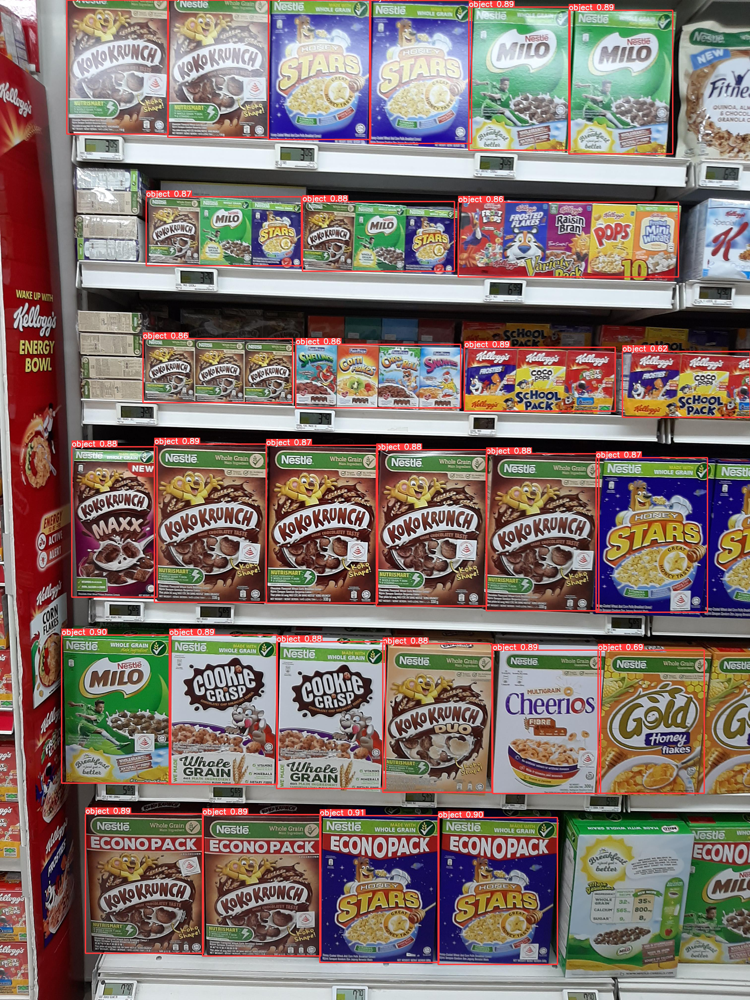

In [ ]:
results = model_multi(image_path+img)
df =results.pandas().xyxy[0]
df.drop(['class','name','confidence'], axis=1, inplace=True)
results.render()
cv2_imshow(cv2.cvtColor(results.imgs[0], cv2.COLOR_BGR2RGB))

In [ ]:
df

,xmin,ymin,xmax,ymax
0,1289.471191,3288.556152,1769.714844,3880.683838
1,1766.750244,3296.586426,2247.152832,3888.105713
2,248.468475,2560.802979,688.525024,3157.015137
3,622.179993,1790.383911,1073.949829,2428.299316
4,1082.479858,0.000000,1494.905518,562.593201
5,344.743774,3281.779297,819.185242,3843.129150
6,816.057251,3284.396729,1293.576416,3854.710449
7,1490.261353,1.068032,1901.395630,578.001709
8,1986.205322,2621.423828,2421.863770,3199.133789
9,1890.517090,28.629354,2298.695557,605.129578


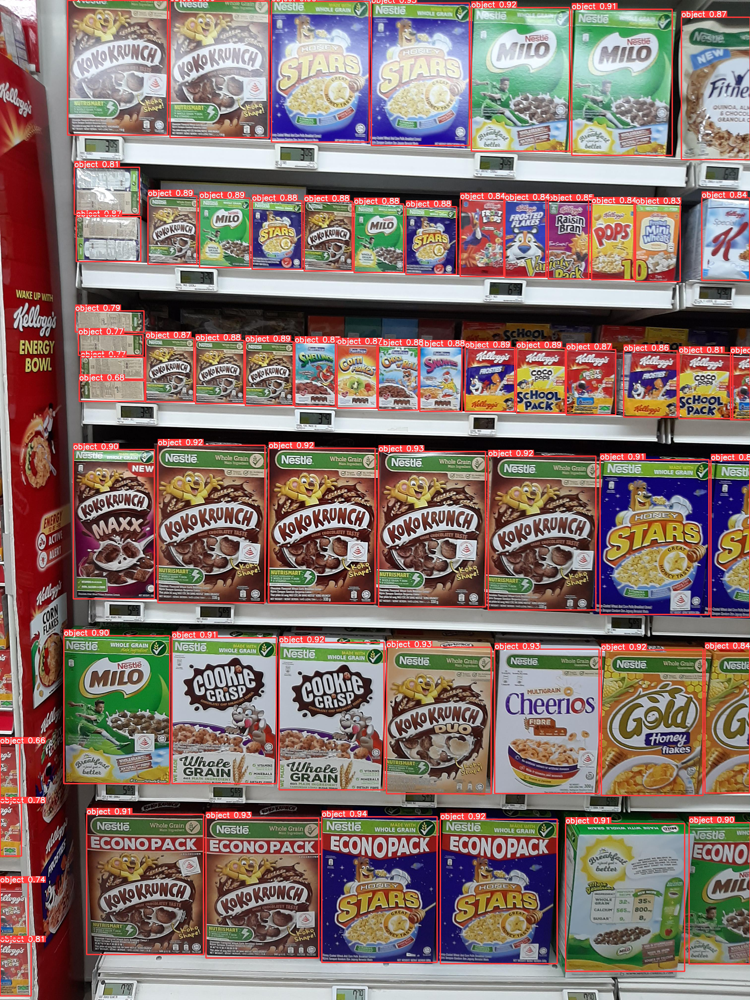

In [ ]:
results = model_full(image_path+img)
df =results.pandas().xyxy[0]
df.drop(['class','name','confidence'], axis=1, inplace=True)
results.render()
cv2_imshow(cv2.cvtColor(results.imgs[0], cv2.COLOR_BGR2RGB))

# Combined Results from detectors

In [ ]:
df_final

,xmin,ymin,xmax,ymax,confidence
0,1289.471191,3288.556152,1769.714844,3880.683838,0.906673
1,1766.750244,3296.586426,2247.152832,3888.105713,0.901832
2,248.468475,2560.802979,688.525024,3157.015137,0.896917
3,622.179993,1790.383911,1073.949829,2428.299316,0.893037
4,1082.479858,0.000000,1494.905518,562.593201,0.893018
5,344.743774,3281.779297,819.185242,3843.129150,0.892194
6,816.057251,3284.396729,1293.576416,3854.710449,0.891341
7,1490.261353,1.068032,1901.395630,578.001709,0.890977
8,1986.205322,2621.423828,2421.863770,3199.133789,0.890714
9,1890.517090,28.629354,2298.695557,605.129578,0.888289


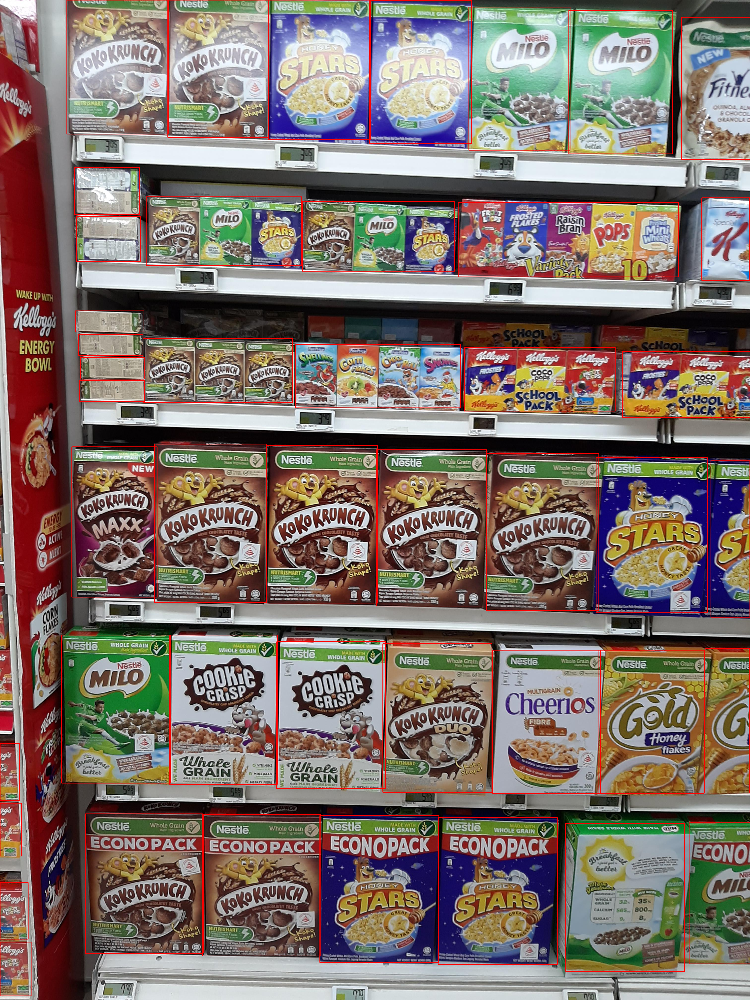

In [ ]:
s_im = cv2.imread(image_path+img)
for i in range(df_final.shape[0]):
  row =df_final.iloc[i]
  xmin = row['xmin']
  ymin = row['ymin']
  xmax = row['xmax']
  ymax = row['ymax']
  confidence = row['confidence']
  color = (0, 0, 255)
  pt1 = (int(xmin), int(ymin))
  pt2 = (int(xmax), int(ymax))
  cv2.rectangle(s_im, pt1, pt2, color,2)
cv2_imshow(s_im)